0.4%

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /home/frozxn/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100.0%


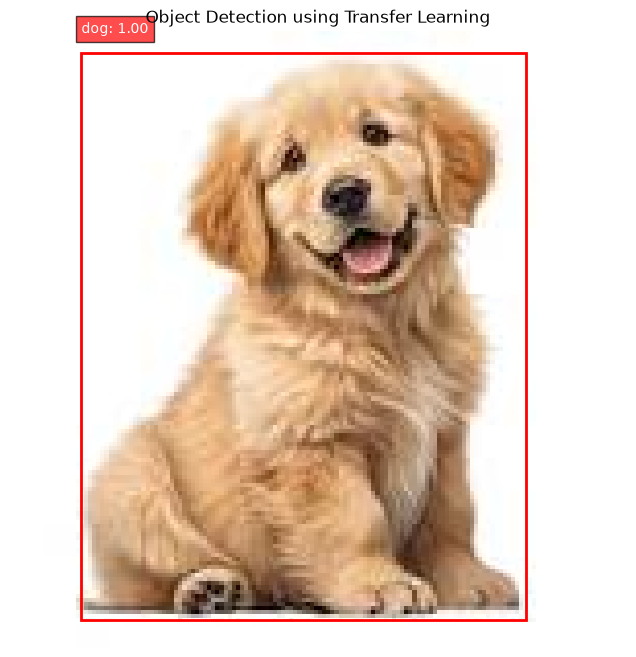

Code execution complete.
Objects detected: 1


In [4]:
# Object Detection using Transfer Learning (Faster R-CNN)

import os
import torch
import torchvision
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from tkinter import Tk, filedialog

# 1. Select an image from your computer
root = Tk()
root.withdraw()

image_path = filedialog.askopenfilename(
    title="Select an Image",
    filetypes=[
        ("Image Files", "*.jpg *.jpeg *.png")
    ]
)

root.destroy()

# Check image selection
if not image_path:
    print("No image selected!")
else:

    # 2. Load and preprocess the image
    image = Image.open(image_path).convert("RGB")

    weights = torchvision.models.detection.FasterRCNN_ResNet50_FPN_Weights.DEFAULT

    model = torchvision.models.detection.fasterrcnn_resnet50_fpn(
        weights=weights
    )

    model.eval()

    transform = weights.transforms()
    image_tensor = transform(image)

    # 3. Detect objects
    with torch.no_grad():
        predictions = model([image_tensor])[0]

    # 4. Get class names
    categories = weights.meta["categories"]
    threshold = 0.5

    # 5. Display results
    fig, ax = plt.subplots(figsize=(10, 8))
    ax.imshow(image)

    detected = 0

    for box, label, score in zip(
        predictions["boxes"],
        predictions["labels"],
        predictions["scores"]
    ):

        if score.item() >= threshold:

            x1, y1, x2, y2 = box.tolist()
            label_name = categories[label.item()]

            rect = patches.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                linewidth=2,
                edgecolor="red",
                facecolor="none"
            )

            ax.add_patch(rect)

            ax.text(
                x1,
                max(0, y1 - 5),
                f"{label_name}: {score.item():.2f}",
                color="white",
                bbox=dict(facecolor="red", alpha=0.7)
            )

            detected += 1

    ax.axis("off")
    plt.title("Object Detection using Transfer Learning")
    plt.show()

    print("Code execution complete.")
    print("Objects detected:", detected)